# Conformal prediction intervals

Calibrate prediction intervals from **cross-validation errors on the point forecast** instead of a model's
native quantile head. Pass a [`ConformalIntervals`](../conformal-prediction.md) object as
`prediction_intervals` when you create a model, then request `level` (or `quantiles`) in `forecast()` as usual.
See [Conformal prediction](../conformal-prediction.md) for the full API.

In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot]"

**Dataset:** hourly day-ahead electricity prices for five markets (BE, DE, FR, NP, PJM), the same panel as
the [exogenous variables](exogenous-variables.ipynb) example. We only use the target here. Horizon length is
**24 hours** (`h=24`).

**Why conformal here:** many foundation models predict a **fixed set of quantile knots**. **Tafsut** and
**Chronos-Bolt** both stop at the 0.1 and 0.9 quantiles, so any level wider than 80% is clamped to the 80%
interval: their "95%" interval is really an 80% one. Conformal intervals are built from the model's own past
errors, so they can be as wide as the data requires.

**Models in this example:** Tafsut and Chronos-Bolt, each twice: once with native quantiles and once with
conformal intervals. Each pair shares the same point forecast, so any difference comes from the intervals.

**Caveats:**
- Calibration costs about **`n_windows` extra forecasts per series**, on top of the final forecast.
- Each series needs at least **`n_windows * h + 1`** observations.
- **`cross_validation()`** recalibrates the conformal models at every cutoff, using only data before it.
  `detect_anomalies()` keeps using native quantiles.

## How conformal intervals are built

Calibration runs separately for every `unique_id`. Let $T$ be the last observed timestamp, $h$ the horizon and
$W$ = `n_windows`.

**1. Backtest the point forecast.** For each window $w = 1, \dots, W$ the model forecasts $h$ steps from the cutoff
$t_w = T - (W - w + 1)\,h$, using only data up to $t_w$, and we keep the absolute error at every horizon step
$j = 1, \dots, h$:

$$
e_{w,j} = \left|\, y_{t_w + j} - \hat{y}_{t_w + j \mid t_w} \right|
$$

**2. Forecast.** The model produces the point forecast $\hat{y}_{T+j}$ from the full history, unchanged.

**3. Build the interval.** For a level $L$ (in percent) let $\alpha = 1 - L/100$. The default
`conformal_distribution` method forms $2W$ synthetic outcomes around the point forecast,

$$
S_j = \{\hat{y}_{T+j} - e_{w,j}\}_{w=1}^{W} \cup \{\hat{y}_{T+j} + e_{w,j}\}_{w=1}^{W},
$$

and returns their symmetric quantiles as the interval:

$$
\Big[\, \mathrm{Quantile}_{\alpha/2}(S_j),\; \mathrm{Quantile}_{1-\alpha/2}(S_j) \,\Big]
$$

`conformal_error` instead adds and subtracts $\hat{q}_j = \mathrm{Quantile}_{1-\alpha}(e_{1,j}, \dots, e_{W,j})$.
Either way, every series and every horizon step gets its own width, and wider levels reach further into the
error distribution instead of stopping at a fixed knot.

## Import libraries

In [2]:
import pandas as pd

from foundationforecast import ConformalIntervals, FoundationForecast

## Load the dataset

The DataFrame must include at least the following columns:
- `unique_id`: series identifier (string)
- `ds`: timestamp (datetime)
- `y`: target (float)

The source file also ships two exogenous columns. We drop them to keep this example univariate.

The pandas frequency is inferred from `ds` when `freq` is omitted.

In [3]:
DATA = "https://timecopilot.s3.amazonaws.com/public/data/electricity_price"
df = pd.read_parquet(f"{DATA}/train.parquet")[["unique_id", "ds", "y"]]
df.head()

,unique_id,ds,y
0,BE,2011-01-09 00:00:00,32.540001
1,BE,2011-01-09 01:00:00,21.549999
2,BE,2011-01-09 02:00:00,15.710000
3,BE,2011-01-09 03:00:00,10.580000
4,BE,2011-01-09 04:00:00,10.320000


## Plot the data

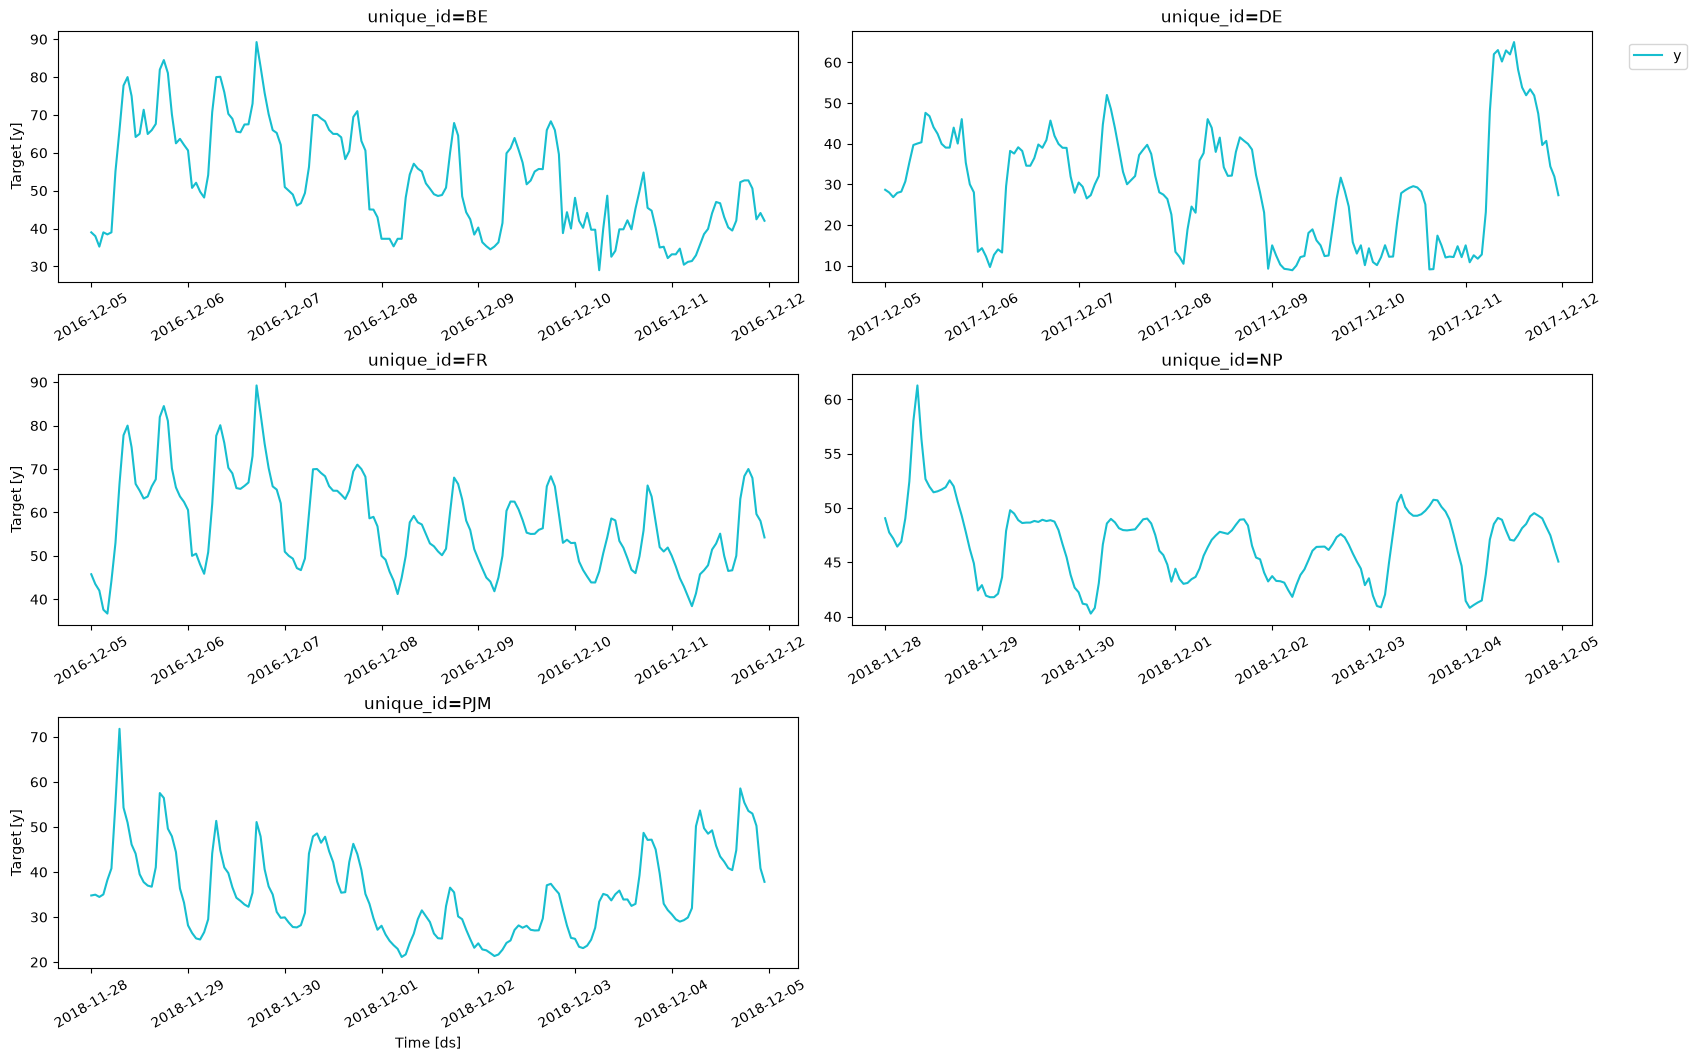

In [4]:
FoundationForecast.plot(df, max_insample_length=24 * 7)

## Import the models

In [5]:
from foundationforecast.models import Chronos, Tafsut

## Create a FoundationForecast

Each model appears twice with a distinct **`alias`**. The `-conformal` copies receive
`prediction_intervals=ConformalIntervals(...)`; the others keep their native quantiles.

`n_windows=14` calibrates on the last two weeks of each series (one window per day at `h=24`), which gives
$W = 14$ errors per horizon step. More windows make the tails, and therefore wide levels like 95%, more
stable at the cost of more forecasts. `h` is taken from `forecast(h=...)`.

In [6]:
models = [
    Tafsut(alias="Tafsut", context_length=2048),
    Tafsut(
        alias="Tafsut-conformal",
        context_length=2048,
        prediction_intervals=ConformalIntervals(n_windows=14),
    ),
    Chronos(repo_id="amazon/chronos-bolt-small", alias="Chronos-Bolt"),
    Chronos(
        repo_id="amazon/chronos-bolt-small",
        alias="Chronos-Bolt-conformal",
        prediction_intervals=ConformalIntervals(n_windows=14),
    ),
]

ff = FoundationForecast(models=models)

## Cross validation

`cross_validation()` evaluates the models on the last `n_windows` days of each series. For the conformal
models, every window is recalibrated on the 14 days before its cutoff, so the evaluation never sees the
data it is scored on.

In [7]:
h = 24
level = [80, 95]

cv_df = ff.cross_validation(df=df, h=h, n_windows=7, level=level)
cv_df.head()

,unique_id,ds,cutoff,y,Tafsut,Tafsut-lo-80,Tafsut-hi-80,Tafsut-lo-95,Tafsut-hi-95,Tafsut-conformal,...,Chronos-Bolt,Chronos-Bolt-lo-80,Chronos-Bolt-hi-80,Chronos-Bolt-lo-95,Chronos-Bolt-hi-95,Chronos-Bolt-conformal,Chronos-Bolt-conformal-lo-95,Chronos-Bolt-conformal-lo-80,Chronos-Bolt-conformal-hi-80,Chronos-Bolt-conformal-hi-95
0,BE,2016-12-05 00:00:00,2016-12-04 23:00:00,39.000000,36.115623,32.066383,41.273872,32.066383,41.273872,36.115623,...,38.530754,32.027889,44.170807,32.027889,44.170807,38.530754,13.392504,20.321233,56.740275,63.669004
1,BE,2016-12-05 01:00:00,2016-12-04 23:00:00,38.009998,34.310760,30.621126,39.170567,30.621126,39.170567,34.310760,...,36.210449,30.658821,40.730682,30.658821,40.730682,36.210449,12.460238,22.040014,50.380884,59.960660
2,BE,2016-12-05 02:00:00,2016-12-04 23:00:00,35.230000,32.888016,28.999914,37.718555,28.999914,37.718555,32.888016,...,34.465965,30.374836,37.649826,30.374836,37.649826,34.465965,16.688360,26.039836,42.892095,52.243571
3,BE,2016-12-05 03:00:00,2016-12-04 23:00:00,39.000000,31.779091,27.831749,37.416550,27.831749,37.416550,31.779091,...,34.234600,30.240908,37.297134,30.240908,37.297134,34.234600,20.653054,26.801954,41.667247,47.816147
4,BE,2016-12-05 04:00:00,2016-12-04 23:00:00,38.459999,31.067841,27.448444,37.807102,27.448444,37.807102,31.067841,...,32.798935,28.782866,38.046753,28.782866,38.046753,32.798935,17.375985,23.953693,41.644176,48.221885


The clamping is easy to check: for the native fixed-knot models, the 95% bounds are identical to the 80% ones.

In [8]:
for alias in ["Tafsut", "Chronos-Bolt", "Tafsut-conformal", "Chronos-Bolt-conformal"]:
    same = (cv_df[f"{alias}-lo-95"] == cv_df[f"{alias}-lo-80"]).all()
    print(f"{alias:<24} 95% interval == 80% interval: {same}")

Tafsut                   95% interval == 80% interval: True
Chronos-Bolt             95% interval == 80% interval: True
Tafsut-conformal         95% interval == 80% interval: False
Chronos-Bolt-conformal   95% interval == 80% interval: False


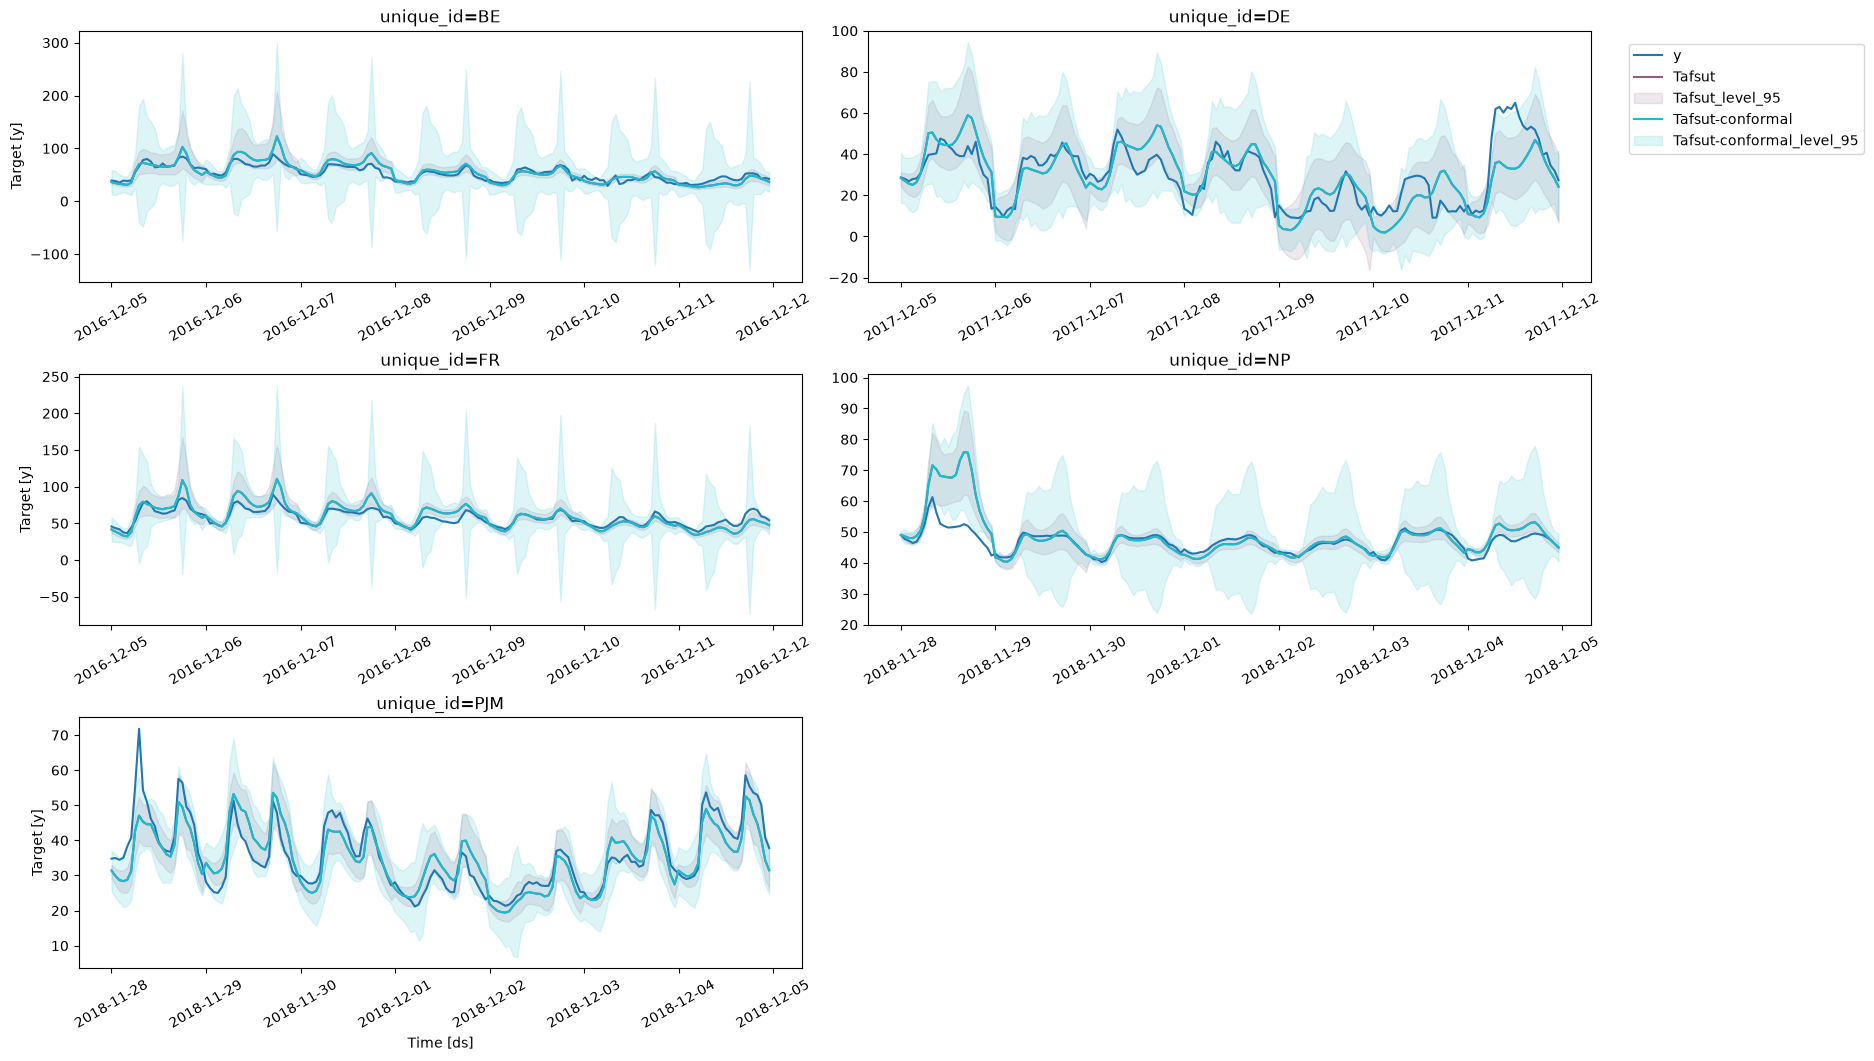

In [9]:
ff.plot(
    df,
    cv_df.drop(columns=["cutoff", "y"]),
    models=["Tafsut", "Tafsut-conformal"],
    level=[95],
    max_insample_length=24 * 7,
)

## Evaluation

**Coverage** is the share of actuals that fall inside each interval; a well-calibrated $L$% interval should
cover about $L/100$ of them. We also report **MASE** (point accuracy, identical within each pair because they
share the point forecast) and **scaled CRPS** computed from the interval bounds.

In [10]:
from functools import partial

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import coverage, mase, scaled_crps

In [11]:
eval_df = evaluate(
    cv_df.drop(columns=["cutoff"]),
    train_df=df,
    metrics=[partial(mase, seasonality=24), scaled_crps, coverage],
    level=level,
)
eval_df.groupby("metric").mean(numeric_only=True).T.round(3)

metric,coverage_level80,coverage_level95,mase,scaled_crps
Tafsut,0.745,0.745,0.790,0.044
Tafsut-conformal,0.802,0.937,0.790,0.048
Chronos-Bolt,0.777,0.777,0.877,0.047
Chronos-Bolt-conformal,0.839,0.943,0.877,0.053


Coverage only means something next to **width**: an interval can always reach 95% coverage by being huge.
Average width of each interval per model:

In [12]:
pd.DataFrame(
    {
        f"width_{lv}": {
            m.alias: (cv_df[f"{m.alias}-hi-{lv}"] - cv_df[f"{m.alias}-lo-{lv}"]).mean()
            for m in models
        }
        for lv in level
    }
).round(2)

,width_80,width_95
Tafsut,16.82,16.82
Tafsut-conformal,20.27,45.20
Chronos-Bolt,18.37,18.37
Chronos-Bolt-conformal,24.05,46.72


**Reading the results:**
- Native **95%** coverage is about **0.75–0.78**, the same as their 80% coverage, because the 95% interval is
  clamped to the outermost 0.1 / 0.9 knots. Their nominal 95% interval misses roughly one actual in four.
- With conformal intervals, both models reach about **0.94** at 95% and about **0.80–0.84** at 80%, close to the
  nominal levels. The 95% interval is now genuinely wider than the 80% one, reflecting the heavy tails of
  electricity prices.
- MASE is identical within each pair: conformal calibration never changes the point forecast.
- Scaled CRPS, computed here from only two interval levels, is slightly worse for the conformal models because
  their intervals are wider. Conformal intervals buy **calibration**: they don't make the model sharper.

Cross-validation covers 7 windows × 5 markets (35 forecasts of 24 hours).

## Forecast

Forecast the next 24 hours from the full history. Conformal models calibrate on the last `n_windows` days of
`df` before producing their intervals.

In [13]:
fcst_df = ff.forecast(df=df, h=h, level=level)
fcst_df.head()

,unique_id,ds,Tafsut,Tafsut-lo-80,Tafsut-hi-80,Tafsut-lo-95,Tafsut-hi-95,Tafsut-conformal,Tafsut-conformal-lo-95,Tafsut-conformal-lo-80,...,Chronos-Bolt,Chronos-Bolt-lo-80,Chronos-Bolt-hi-80,Chronos-Bolt-lo-95,Chronos-Bolt-hi-95,Chronos-Bolt-conformal,Chronos-Bolt-conformal-lo-95,Chronos-Bolt-conformal-lo-80,Chronos-Bolt-conformal-hi-80,Chronos-Bolt-conformal-hi-95
0,BE,2016-12-12 00:00:00,39.107590,35.773071,42.424500,35.773071,42.424500,39.107590,15.728106,26.094549,...,37.780800,33.799568,41.589775,33.799568,41.589775,37.780800,12.642550,24.076720,51.484880,62.919050
1,BE,2016-12-12 01:00:00,37.518028,34.333977,40.831589,34.333977,40.831589,37.518028,16.644696,27.895403,...,35.581085,31.618849,39.387169,31.618849,39.387169,35.581085,11.830874,26.194343,44.967828,59.331296
2,BE,2016-12-12 02:00:00,36.150246,33.190468,39.554028,33.190468,39.554028,36.150246,19.908976,29.742885,...,35.315460,31.416773,39.073761,31.416773,39.073761,35.315460,22.172372,27.169082,43.461838,48.458548
3,BE,2016-12-12 03:00:00,34.675610,31.934195,39.061707,31.934195,39.061707,34.675610,22.483686,26.337403,...,34.876961,31.027365,38.703415,31.027365,38.703415,34.876961,22.824098,25.993547,43.760375,46.929823
4,BE,2016-12-12 04:00:00,34.736134,31.831902,39.659538,31.831902,39.659538,34.736134,22.659491,26.232497,...,34.775879,30.831865,39.205643,30.831865,39.205643,34.775879,24.296711,26.328587,43.223171,45.255047


## Plot forecast

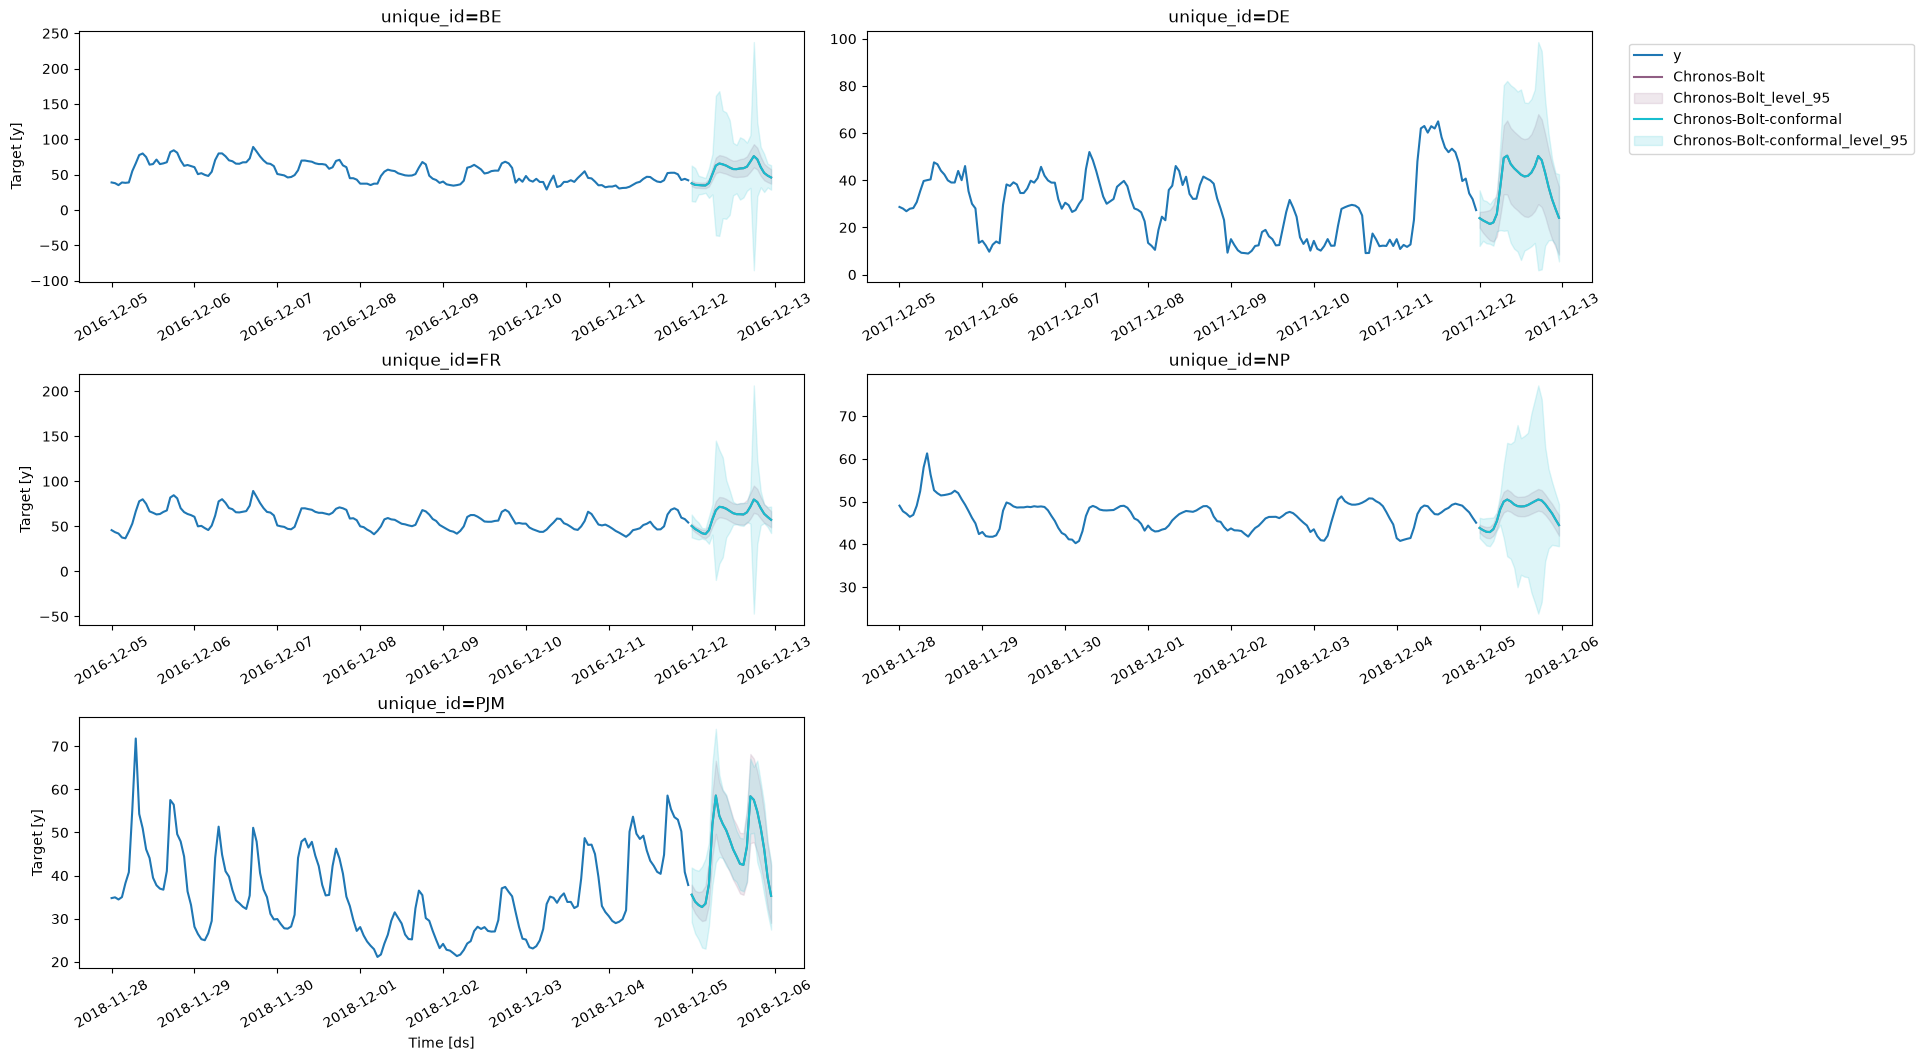

In [14]:
ff.plot(
    df,
    fcst_df,
    models=["Chronos-Bolt", "Chronos-Bolt-conformal"],
    level=[95],
    max_insample_length=24 * 7,
)